# 03 - What is associated with distrust? Logistic regression
Outcome: `distrusts_ai` (somewhat/highly distrust). Sample: professional developers who use AI. Robust (HC1) SEs.

* **M1** pooled 2023-2025 (year + experience + role + company size + country + age)
* **M1b** M1 + task types offered in all years
* **M2a/b/c** 2025 nested models: demographics -> + usage (frequency, agents, tasks) -> + frustrations

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

In [2]:
fit = pd.read_csv("reports/tables/model_fit.csv"); fit.round(3)

,model,n,events,pseudo_r2,aic,n_params,dropped_rows
0,M1 pooled,78534,24035,0.049,92050.713,48,0
1,M1b pooled + tasks,75481,23278,0.077,86176.112,56,0
2,M2a,18651,7246,0.056,23615.497,45,0
3,M2b,18651,7246,0.134,21692.808,62,0
4,M2c,18651,7246,0.167,20896.285,67,0


In [3]:
coef = pd.read_csv("reports/tables/model_coefficients.csv")
key = coef[coef.label.str.contains("Year:|Experience:|Frustration|AI use frequency|AI agents", regex=True) & ~coef.label.str.contains("Missing")]
key[["model", "label", "odds_ratio", "or_low", "or_high", "p_value", "ame_pp"]].round(3)

,model,label,odds_ratio,or_low,or_high,p_value,ame_pp
1,M1 pooled,Year: 2024 (vs 2023),1.472,1.416,1.529,0.000,7.807
2,M1 pooled,Year: 2025 (vs 2023),1.869,1.793,1.949,0.000,13.116
3,M1 pooled,Experience: 10-19 yrs (vs 0-4 yrs),1.726,1.611,1.850,0.000,11.115
4,M1 pooled,Experience: 20-29 yrs (vs 0-4 yrs),2.143,1.971,2.329,0.000,16.218
5,M1 pooled,Experience: 30+ yrs (vs 0-4 yrs),3.074,2.774,3.406,0.000,24.554
6,M1 pooled,Experience: 5-9 yrs (vs 0-4 yrs),1.275,1.193,1.363,0.000,4.914
49,M1b pooled + tasks,Year: 2024 (vs 2023),1.543,1.484,1.606,0.000,8.478
50,M1b pooled + tasks,Year: 2025 (vs 2023),1.906,1.821,1.996,0.000,13.149
51,M1b pooled + tasks,Experience: 10-19 yrs (vs 0-4 yrs),1.588,1.477,1.706,0.000,9.090
52,M1b pooled + tasks,Experience: 20-29 yrs (vs 0-4 yrs),1.915,1.755,2.089,0.000,13.270


### Reading the results
* **Odds ratio > 1** = more likely to distrust, holding the other variables constant.
* **AME (pp)** = average change in the probability of distrust, in percentage points.
* Everything is an association in self-selected, cross-sectional data - not a cause.

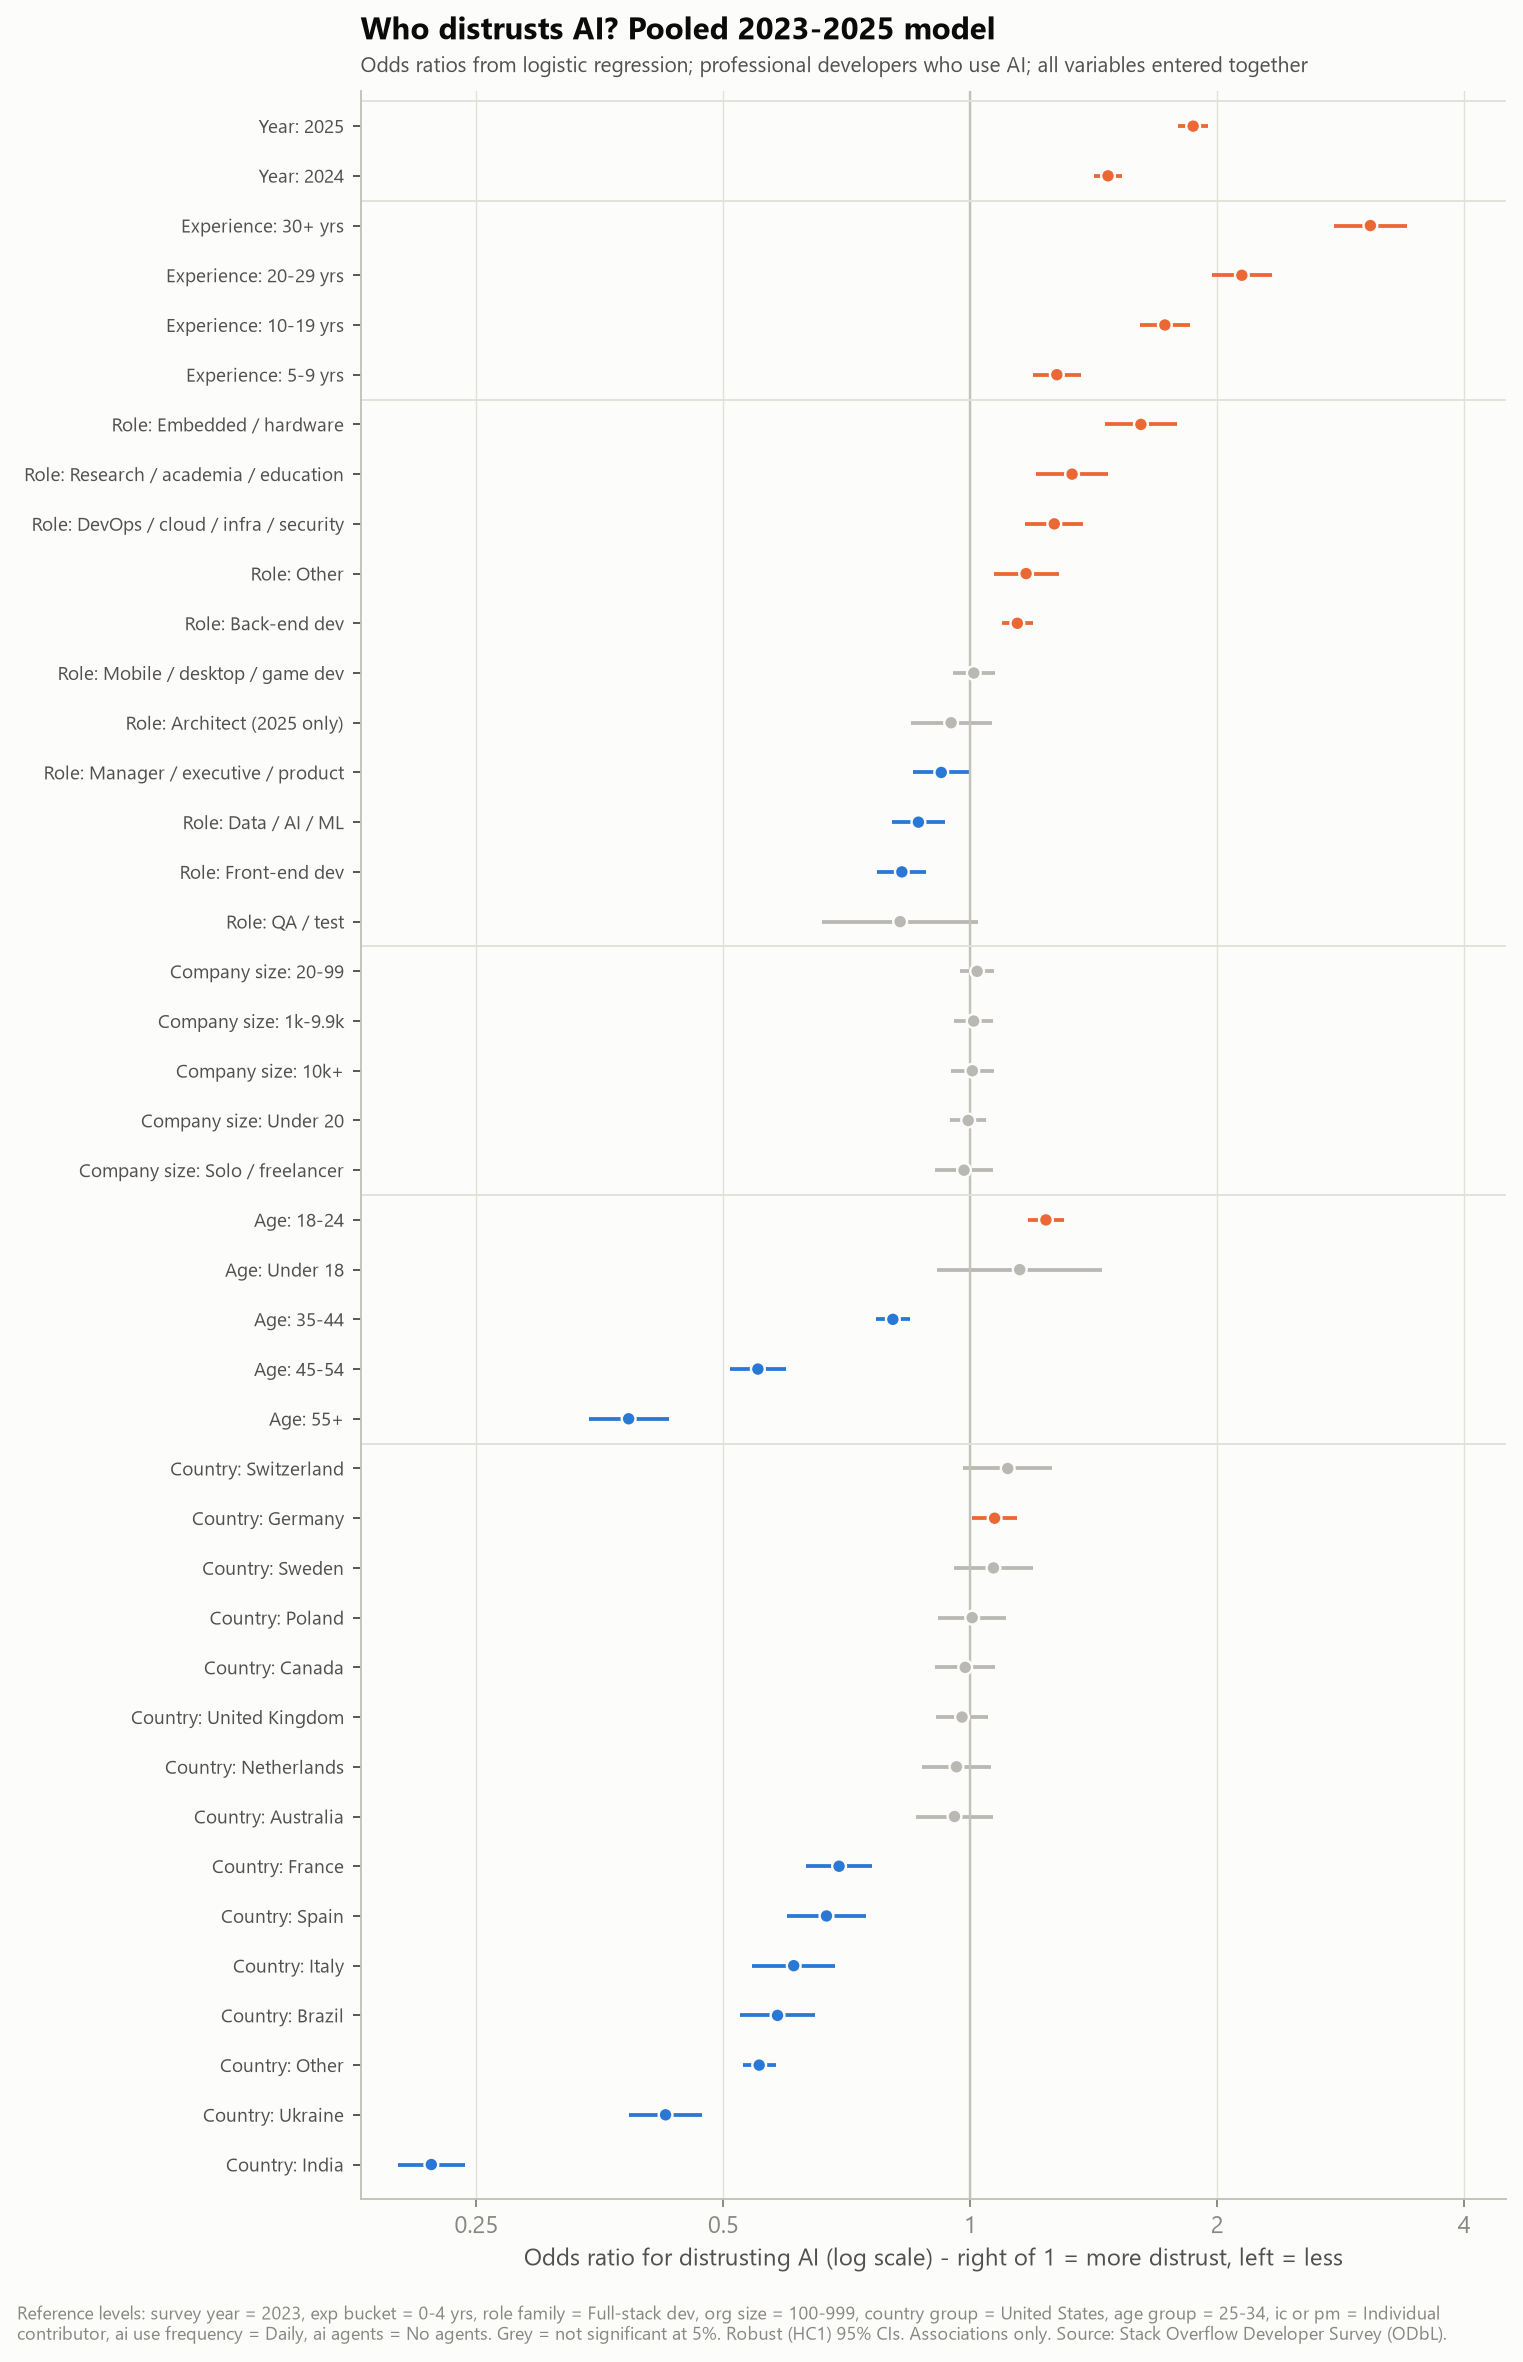

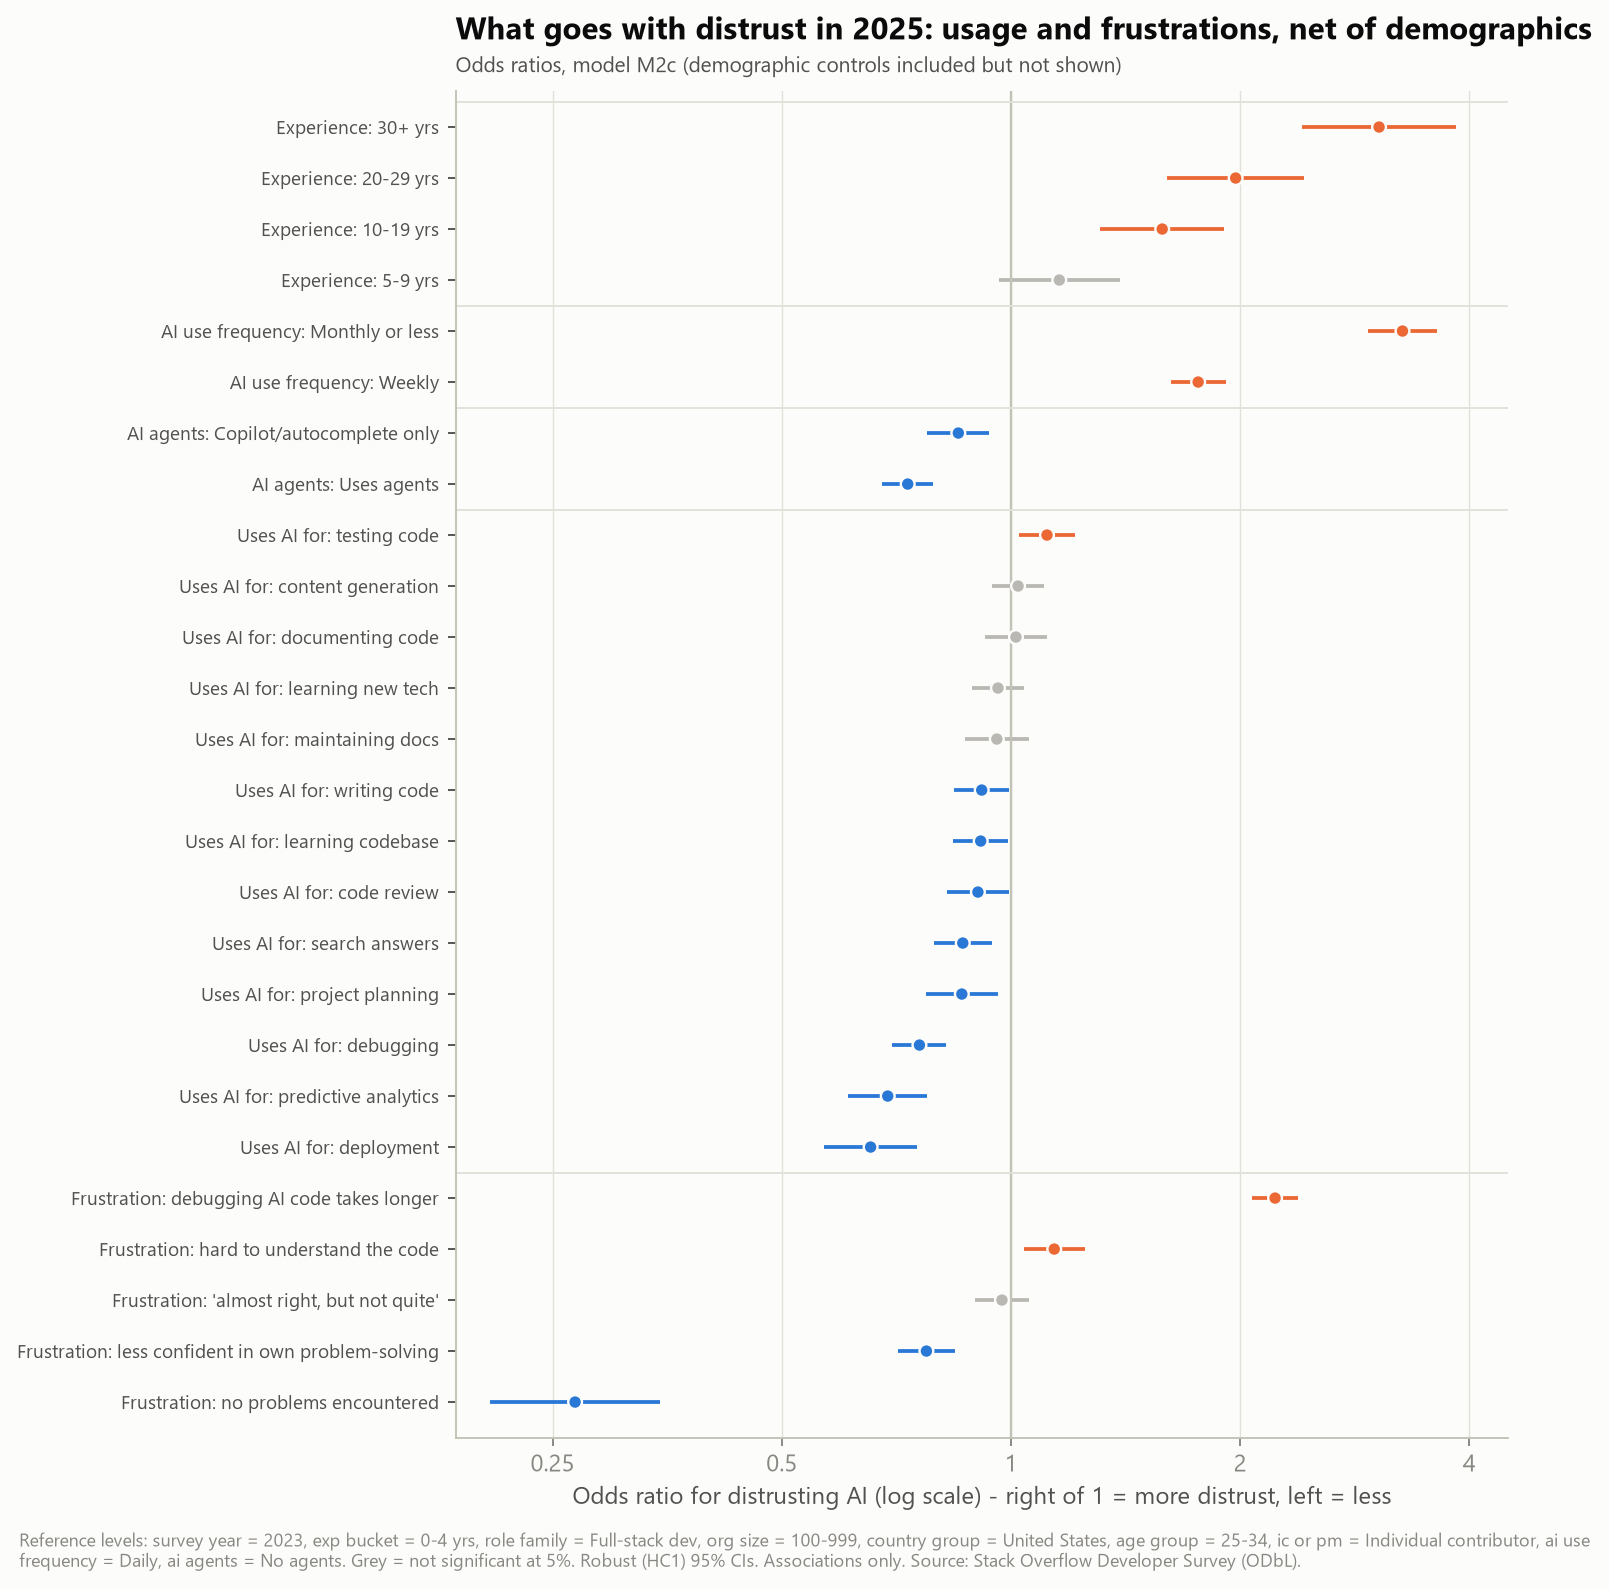

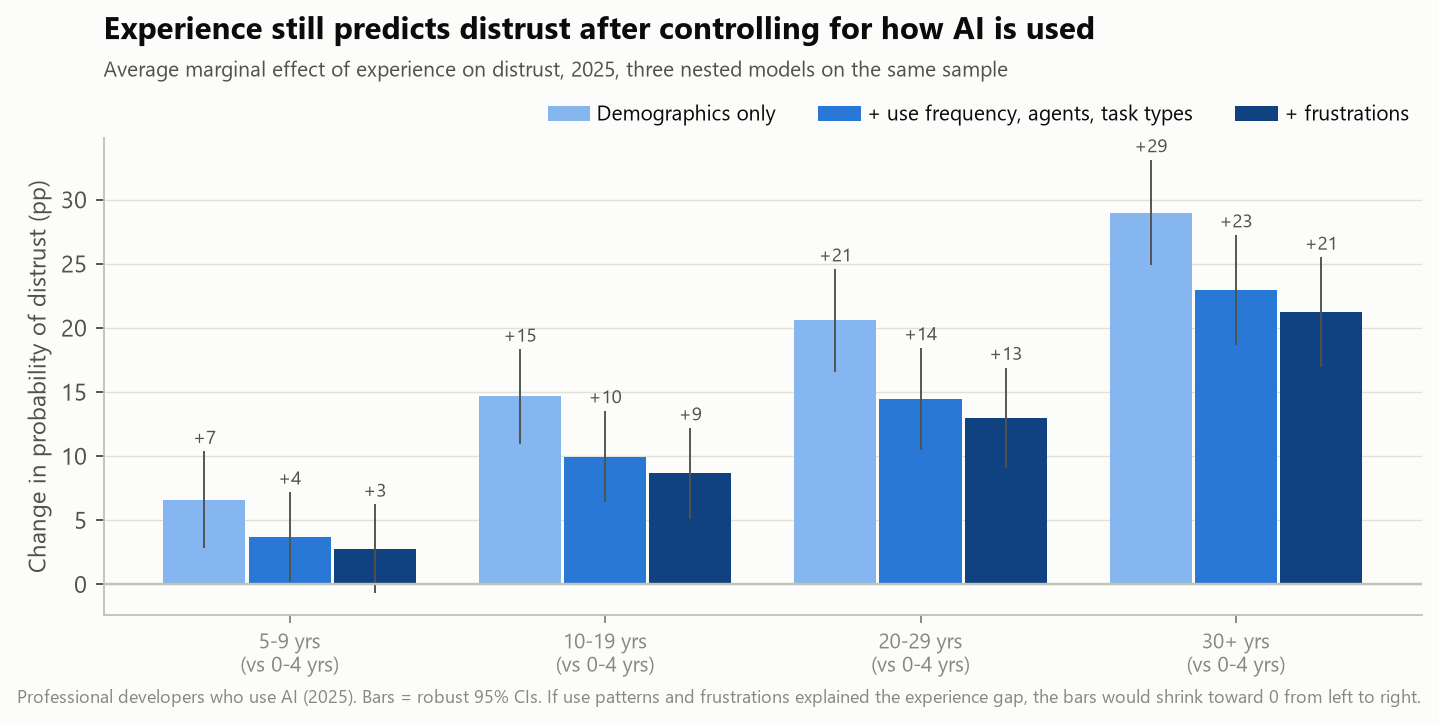

In [4]:
for f in ["fig12a_forest_pooled", "fig12b_forest_2025", "fig13_experience_effect_stepwise"]:
    display(Image(f"reports/figures/{f}.png", width=820))

### Re-fit one model live (to show the code path)

In [5]:
from src.models import prepare, fit as fit_model, c, DEMOGRAPHICS
dd = prepare()
res, tab, stats = fit_model(f"distrusts_ai ~ {c('survey_year')} + {DEMOGRAPHICS}", dd, "M1 pooled")
print(stats); tab[tab.label.str.startswith(("Year", "Experience"))][["label", "odds_ratio", "or_low", "or_high", "ame_pp"]].round(3)

{'model': 'M1 pooled', 'n': 78534, 'events': 24035, 'pseudo_r2': np.float64(0.049447858918481136), 'aic': np.float64(92050.71338708891), 'n_params': 48, 'dropped_rows': 0}


,label,odds_ratio,or_low,or_high,ame_pp
1,Year: 2024 (vs 2023),1.472,1.416,1.529,7.807
2,Year: 2025 (vs 2023),1.869,1.793,1.949,13.116
3,Experience: 10-19 yrs (vs 0-4 yrs),1.726,1.611,1.850,11.115
4,Experience: 20-29 yrs (vs 0-4 yrs),2.143,1.971,2.329,16.218
5,Experience: 30+ yrs (vs 0-4 yrs),3.074,2.774,3.406,24.554
6,Experience: 5-9 yrs (vs 0-4 yrs),1.275,1.193,1.363,4.914
7,Experience: Missing (vs 0-4 yrs),0.998,0.798,1.248,-0.042
